# k-NN on Iris, MNIST, and ImageNet: A Worksheet

**Goal:** take one algorithm --- $k$-nearest neighbours --- and run the same workflow on
three datasets of increasing difficulty:

| Dataset | Samples | Features | Classes | Why it is interesting |
|---|---|---|---|---|
| Iris | 150 | 4 | 3 | small, clean, easy to visualise |
| MNIST | 70,000 | 784 | 10 | real handwritten digits, medium dimension |
| ImageNet | ~1.3M | millions | 1000 | natural images, very high dimension |

For each dataset we will

1. load and inspect the data,
2. split into train and test **before** any preprocessing,
3. standardise the features,
4. choose $k$ by cross-validation,
5. evaluate on the held-out test set and inspect the confusion matrix.

The worksheet deliberately uses the same code path three times. The differences in
accuracy and running time are the lesson.

## Two practical notes

- **MNIST** is downloaded from OpenML. If the download fails (for example offline), the
  notebook falls back automatically to scikit-learn's 8x8 `digits` dataset.
- **ImageNet** is far too large to download here. This notebook expects a local copy of
  the ImageNet folders. If none is found, it builds a small **synthetic image dataset**
  with the same folder layout so that every cell still runs. The workflow is identical;
  only the images change.

## 1. Setup

The setup is deliberately split into two cells. The first one imports only the
lightweight libraries and sets the runtime options, so it finishes immediately. The second
one imports matplotlib and scikit-learn; on a fresh machine it can take 10--30 seconds
because matplotlib builds its font cache once. Later runs take about a second.

Only NumPy, matplotlib, and scikit-learn are required for the fallbacks. Loading a real
ImageNet folder additionally needs Pillow (`pip install pillow`). The random seed is fixed
so the runs are reproducible.

> **MNIST download:** Part 2 tries to download about 70 MB from OpenML. Set
> `DOWNLOAD_MNIST = False` in the next cell (or start Jupyter with `KNN_FORCE_DIGITS=1`)
> to skip it and use the fast `digits` fallback instead.

In [1]:
import os
from pathlib import Path
from time import perf_counter

import numpy as np

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# Runtime options. Set DOWNLOAD_MNIST = False to skip the OpenML download;
# the environment variable KNN_FORCE_DIGITS=1 has the same effect.
DOWNLOAD_MNIST = os.environ.get("KNN_FORCE_DIGITS", "0") != "1"

print("Core setup complete.")

Core setup complete.


The next cell is the expensive one on a first run. It imports matplotlib (which may spend
10--30 seconds building its font cache) and scikit-learn. The progress messages show which
import is running.

In [2]:
print("Importing matplotlib (first run may build the font cache)...", flush=True)
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

print("Importing scikit-learn...", flush=True)
from sklearn.datasets import fetch_openml, load_digits, load_iris
from sklearn.decomposition import PCA
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    confusion_matrix,
)
from sklearn.model_selection import (
    StratifiedKFold,
    cross_val_score,
    train_test_split,
)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

plt.rcParams.update(
    {
        "figure.figsize": (8, 5),
        "axes.grid": True,
        "grid.alpha": 0.3,
        "axes.spines.top": False,
        "axes.spines.right": False,
    }
)
print("Scientific libraries ready.")

Importing matplotlib (first run may build the font cache)...
Importing scikit-learn...
Scientific libraries ready.


### 1.1 Reusable helpers

All three parts share the same model-selection and plotting helpers. Keeping them in one
place makes the comparison fair: the only thing that changes between datasets is the
data.

In [3]:
def build_knn_pipeline(k, n_components=None, random_state=RANDOM_STATE):
    # Standardise, optionally reduce with PCA, then classify with k-NN.
    steps = [("scaler", StandardScaler())]
    if n_components is not None:
        steps.append(("pca", PCA(n_components=n_components, random_state=random_state)))
    steps.append(("knn", KNeighborsClassifier(n_neighbors=int(k), n_jobs=-1)))
    return Pipeline(steps)


def tune_k(X, y, ks, cv_splits=3, n_components=None, random_state=RANDOM_STATE):
    # Cross-validated accuracy for every candidate k.
    cv = StratifiedKFold(n_splits=cv_splits, shuffle=True, random_state=random_state)
    rows = []
    for k in ks:
        model = build_knn_pipeline(k, n_components=n_components, random_state=random_state)
        scores = cross_val_score(model, X, y, cv=cv, scoring="accuracy")
        rows.append(
            {"k": int(k), "mean": float(scores.mean()), "std": float(scores.std())}
        )
    return rows


def best_row(rows):
    return max(rows, key=lambda row: row["mean"])


def plot_k_curve(rows, title):
    ks = [row["k"] for row in rows]
    means = np.array([row["mean"] for row in rows])
    stds = np.array([row["std"] for row in rows])
    j = int(np.argmax(means))

    fig, ax = plt.subplots()
    ax.errorbar(ks, means, yerr=stds, marker="o", capsize=3)
    ax.axvline(ks[j], color="k", linestyle=":", label=f"best k = {ks[j]}")
    ax.set_xlabel("$k$")
    ax.set_ylabel("Cross-validated accuracy")
    ax.set_title(title)
    ax.legend()
    plt.show()


def plot_image_gallery(images, labels, class_names, shape, n=12, title=""):
    # Show a grid of images; works for grayscale (2-D) and RGB (3-D) inputs.
    n = min(n, len(images))
    cols = 6
    n_rows = int(np.ceil(n / cols))
    fig, axes = plt.subplots(n_rows, cols, figsize=(cols * 1.7, n_rows * 2.0))
    axes = np.atleast_2d(axes)
    for ax in axes.ravel():
        ax.axis("off")
    for ax, img, label in zip(axes.ravel(), images[:n], labels[:n]):
        if img.ndim == 3:
            ax.imshow(img)
        else:
            ax.imshow(img.reshape(shape), cmap="gray")
        ax.set_title(str(class_names[label]), fontsize=9)
    if title:
        fig.suptitle(title)
    fig.tight_layout()
    plt.show()


def fit_and_time(model, x_train, y_train, x_test, y_test):
    # Fit, predict, and report accuracy plus per-query prediction time.
    model.fit(x_train, y_train)
    model.predict(x_test[:5])  # warm-up
    start = perf_counter()
    y_pred = model.predict(x_test)
    elapsed = perf_counter() - start
    return {
        "model": model,
        "y_pred": y_pred,
        "acc": accuracy_score(y_test, y_pred),
        "seconds": elapsed,
        "ms_per_query": 1000.0 * elapsed / len(x_test),
    }

## Part 1 --- Iris

Iris is the smallest possible sanity check: 150 flowers, four measurements, three
species. One species (setosa) is linearly separable from the other two in the petal
features; versicolor and virginica overlap slightly. A good $k$-NN model reaches the
low-to-mid 90s on a held-out set. With only 45 test flowers, a single error moves accuracy
by more than two percentage points, so treat small differences with care.

Because the dataset is tiny, cross-validation is cheap and the decision boundary can be
drawn exactly.

### 1.2 Load and inspect

Source:   scikit-learn load_iris
Samples:  150
Features: 4 -> ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Classes:  3 -> [np.str_('setosa'), np.str_('versicolor'), np.str_('virginica')]
Class counts: [50 50 50]


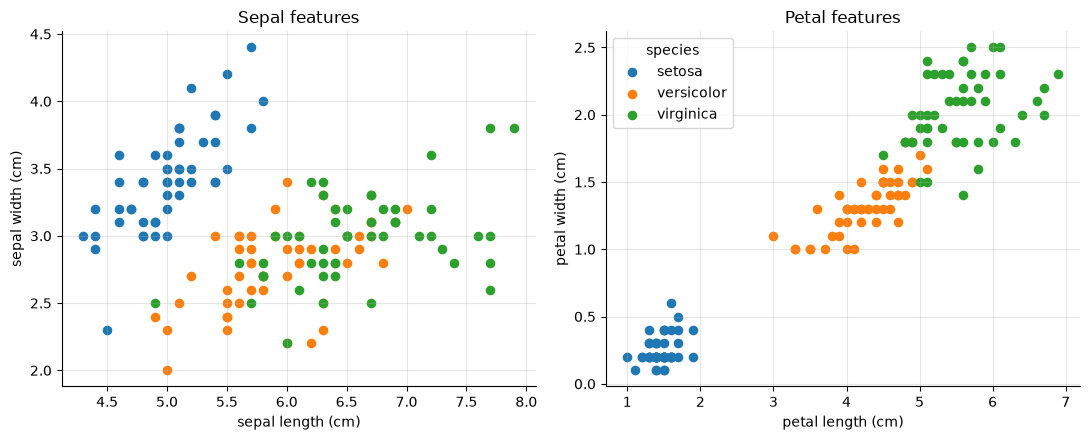

In [5]:
# --- 1. LOAD AND UNPACK THE DATASET ---

# Load the classic Iris flower dataset from scikit-learn
iris = load_iris()

# Separate the input measurements (features) and the flower species IDs (targets)
x_iris, y_iris = iris.data, iris.target

# Convert the array of species names ('setosa', 'versicolor', 'virginica') to a standard Python list
class_names_iris = list(iris.target_names)

# --- 2. INSPECT THE DATASET SUMMARY ---
# Print the data source name
print(f"Source:   scikit-learn load_iris")
# Print the total number of flower samples (rows in the dataset: 150)
print(f"Samples:  {x_iris.shape[0]}")
# Print the number of measurements per flower (columns: 4) and their names
print(f"Features: {x_iris.shape[1]} -> {iris.feature_names}")
# Print the number of flower species (3) and their names
print(f"Classes:  {len(class_names_iris)} -> {class_names_iris}")
# Count and print how many samples belong to each species (50 of each)
print("Class counts:", np.bincount(y_iris))

# --- 3. VISUALIZE THE FEATURES ---
# Create a figure with 1 row and 2 side-by-side subplots, sized 11x4.5 inches
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
# Loop through each species index (0, 1, 2) and its corresponding name
for label, name in enumerate(class_names_iris):
    # Create a True/False filter to isolate only the rows belonging to the current species
    mask = y_iris == label
    # Left plot: scatter plot of sepal length (col 0) vs. sepal width (col 1), with dot size 35
    axes[0].scatter(x_iris[mask, 0], x_iris[mask, 1], s=35, label=name)
    # Right plot: scatter plot of petal length (col 2) vs. petal width (col 3), with dot size 35
    axes[1].scatter(x_iris[mask, 2], x_iris[mask, 3], s=35, label=name)
# Add axis labels and a title to the left subplot
axes[0].set(xlabel="sepal length (cm)", ylabel="sepal width (cm)", title="Sepal features")
# Add axis labels and a title to the right subplot
axes[1].set(xlabel="petal length (cm)", ylabel="petal width (cm)", title="Petal features")
# Display the color legend on the right subplot using the labels defined in the loop
axes[1].legend(title="species")
# Automatically adjust spacing between subplots so labels don't overlap
fig.tight_layout()
# Render and display the final plots on screen
plt.show()

The petal measurements separate the classes far better than the sepal measurements.
$k$-NN will use all four features, but the plot already tells us that most of the signal
lives in petals 3 and 4.

### 1.3 Split first, then scale

The order matters. We split **before** computing the mean and standard deviation, so the
test set never influences preprocessing. This is the simplest form of leakage prevention.

In [7]:
# --- 1. SPLIT THE DATA INTO TRAINING AND TESTING SETS ---

# Split the dataset: 70% for training and 30% for testing (test_size=0.30)
# stratify=y_iris ensures each flower species keeps the exact same proportion in both sets
# random_state locks the random shuffle so you get the exact same split every time you run it
x_ir_train, x_ir_test, y_ir_train, y_ir_test = train_test_split(
    x_iris, y_iris, test_size=0.30, stratify=y_iris, random_state=RANDOM_STATE
)

# Print the row and column counts for the resulting training (105, 4) and test (45, 4) sets
print(f"Train: {x_ir_train.shape}  Test: {x_ir_test.shape}")


# --- 2. STANDARDIZE (SCALE) THE FEATURES ---

# Calculate the mean and standard deviation using ONLY the training data (prevents data leakage)
scaler_ir = StandardScaler().fit(x_ir_train)

# Apply the scaling math to center the training features around 0 with a standard deviation of 1
x_ir_train_s = scaler_ir.transform(x_ir_train)

# Apply that exact same training scale to the test features
x_ir_test_s = scaler_ir.transform(x_ir_test)

# Verify the scaling worked: column means should now equal 0 (rounded to 6 decimal places)
print("Training means after scaling:", np.round(x_ir_train_s.mean(axis=0), 6))

# Verify the scaling worked: column standard deviations should now equal 1
print("Training stds  after scaling:", np.round(x_ir_train_s.std(axis=0), 6))


# --- 3. TRAIN AND EVALUATE A BASELINE MODEL ---

# Create a K-Nearest Neighbors classifier (checking the 5 closest points) and train it on the scaled training data
baseline = KNeighborsClassifier(n_neighbors=5).fit(x_ir_train_s, y_ir_train)

# Test the model on the unseen scaled test data and print its accuracy score to 3 decimal places
print(f"\n5-NN test accuracy (no tuning): {baseline.score(x_ir_test_s, y_ir_test):.3f}")


Train: (105, 4)  Test: (45, 4)
Training means after scaling: [ 0. -0. -0. -0.]
Training stds  after scaling: [1. 1. 1. 1.]

5-NN test accuracy (no tuning): 0.911


### 1.4 Choose $k$ with cross-validation

We try odd values from 1 to 31 with stratified 5-fold cross-validation on the training
set. Odd values avoid ties in a three-class vote. The test set stays untouched until the
next cell.

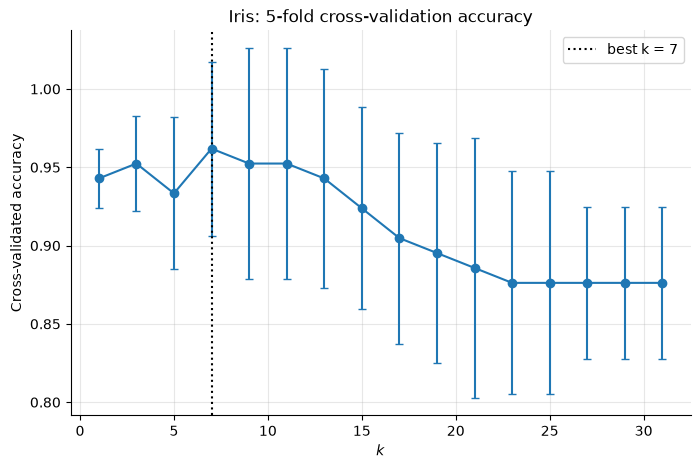

k =  1   CV accuracy = 0.943 +/- 0.019
k =  3   CV accuracy = 0.952 +/- 0.030
k =  5   CV accuracy = 0.933 +/- 0.049
k =  7   CV accuracy = 0.962 +/- 0.056
k =  9   CV accuracy = 0.952 +/- 0.074
k = 11   CV accuracy = 0.952 +/- 0.074
k = 13   CV accuracy = 0.943 +/- 0.070
k = 15   CV accuracy = 0.924 +/- 0.065
k = 17   CV accuracy = 0.905 +/- 0.067
k = 19   CV accuracy = 0.895 +/- 0.070
k = 21   CV accuracy = 0.886 +/- 0.083
k = 23   CV accuracy = 0.876 +/- 0.071
k = 25   CV accuracy = 0.876 +/- 0.071
k = 27   CV accuracy = 0.876 +/- 0.049
k = 29   CV accuracy = 0.876 +/- 0.049
k = 31   CV accuracy = 0.876 +/- 0.049

Selected k = 7 with CV accuracy 0.962


In [9]:
# --- 1. RUN HYPERPARAMETER TUNING ---

# Create a list of odd neighbor counts to test: [1, 3, 5, ..., 31] (odd numbers avoid voting ties)
ks_iris = list(range(1, 32, 2))

# Evaluate each k value using 5-fold cross-validation on the training data
# (Note: Ensure x_ir_train matches your earlier variable name, e.g., x_ir_train or x_ir_train_s)
rows_iris = tune_k(x_ir_train, y_ir_train, ks_iris, cv_splits=5)

# Identify and extract the single best result dictionary from the tuning results
best_iris = best_row(rows_iris)


# --- 2. VISUALIZE TUNING PERFORMANCE ---

# Plot the cross-validation accuracy curve across all tested values of k
plot_k_curve(rows_iris, "Iris: 5-fold cross-validation accuracy")


# --- 3. PRINT DETAILED RESULTS ---

# Loop through the tuning results for every tested k value
for row in rows_iris:
    # Print k (padded to 2 spaces for alignment), the average accuracy, and the standard deviation across the 5 folds
    print(f"k = {row['k']:2d}   CV accuracy = {row['mean']:.3f} +/- {row['std']:.3f}")

# Print a final summary highlighting the winning k value and its average cross-validation score
print(f"\nSelected k = {best_iris['k']} with CV accuracy {best_iris['mean']:.3f}")


The curve is flat over a wide range because Iris is easy. Small $k$ is slightly worse
(high variance), and very large $k$ begins to underfit. On a dataset this small, do not
read too much into one or two percentage points: the cross-validation standard deviation
is of the same order.

### 1.5 Final model, test set, and confusion matrix

k = 7
Test accuracy: 0.933
Prediction time: 15.03 ms total, 0.334 ms per query

              precision    recall  f1-score   support

      setosa      1.000     1.000     1.000        15
  versicolor      0.833     1.000     0.909        15
   virginica      1.000     0.800     0.889        15

    accuracy                          0.933        45
   macro avg      0.944     0.933     0.933        45
weighted avg      0.944     0.933     0.933        45



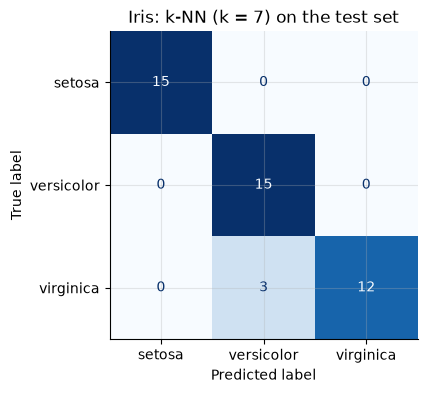

In [12]:
# --- 1. BUILD, TRAIN, AND TIME THE FINAL MODEL ---

# Create a preprocessing + k-NN pipeline using the winning k value found during tuning
iris_model = build_knn_pipeline(best_iris["k"])

# Train the pipeline on the training set, predict on the unseen test set, and record performance metrics
iris_result = fit_and_time(
    iris_model, x_ir_train, y_ir_train, x_ir_test, y_ir_test
)

# Unpack the best k value, overall test accuracy, and average prediction speed per sample
best_k_iris = best_iris["k"]
iris_acc = iris_result["acc"]
iris_ms = iris_result["ms_per_query"]


# --- 2. PRINT ACCURACY, SPEED, AND CLASSIFICATION METRICS ---

# Display the chosen k value and final accuracy on the unseen test set
print(f"k = {best_k_iris}")
print(f"Test accuracy: {iris_acc:.3f}")

# Convert total prediction time from seconds to milliseconds and display both total and per-sample speed
print(f"Prediction time: {iris_result['seconds'] * 1000:.2f} ms total, "
      f"{iris_ms:.3f} ms per query")
print()

# Print a detailed breakdown of precision, recall, and F1-score for each individual flower species
print(classification_report(y_ir_test, iris_result["y_pred"],
                            target_names=class_names_iris, digits=3))


# --- 3. PLOT THE CONFUSION MATRIX ---

# Calculate the confusion matrix comparing true test labels against the model's predictions
cm_iris = confusion_matrix(y_ir_test, iris_result["y_pred"])

# Create a 5x4 inch figure and axis for the plot
fig, ax = plt.subplots(figsize=(5, 4))

# Render the confusion matrix as a blue-shaded grid labeled with the species names (hiding the color bar)
ConfusionMatrixDisplay(cm_iris, display_labels=class_names_iris).plot(
    ax=ax, cmap="Blues", colorbar=False
)

# Add a descriptive title showing the chosen k value and display the final chart
ax.set_title(f"Iris: k-NN (k = {best_k_iris}) on the test set")
plt.show()


### 1.6 What the decision boundary looks like

The model above used all four features. To draw a boundary we refit on the two petal
features. This is a visual aid, not the final model --- the accuracy in this plot will
differ slightly from the four-feature result.

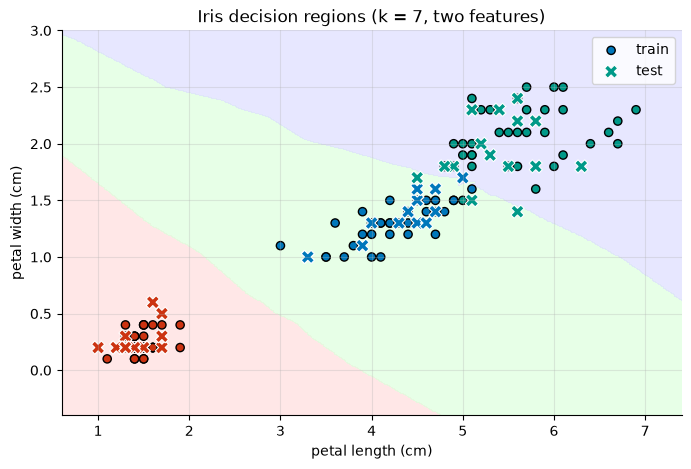

Two-feature test accuracy: 0.911


In [13]:
feature_idx = [2, 3]  # petal length and petal width
x2_train = x_ir_train[:, feature_idx]
x2_test = x_ir_test[:, feature_idx]

boundary_model = build_knn_pipeline(best_k_iris).fit(x2_train, y_ir_train)

x_min, x_max = x2_train[:, 0].min() - 0.5, x2_train[:, 0].max() + 0.5
y_min, y_max = x2_train[:, 1].min() - 0.5, x2_train[:, 1].max() + 0.5
xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 400), np.linspace(y_min, y_max, 400)
)
zz = boundary_model.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)

fig, ax = plt.subplots()
ax.contourf(xx, yy, zz, levels=[-0.5, 0.5, 1.5, 2.5],
            colors=["#FFDDDD", "#DDFFDD", "#DDDDFF"], alpha=0.7)
ax.scatter(x2_train[:, 0], x2_train[:, 1], c=y_ir_train,
           cmap=ListedColormap(["#CC3311", "#0077BB", "#009988"]),
           edgecolor="k", s=35, label="train")
ax.scatter(x2_test[:, 0], x2_test[:, 1], c=y_ir_test, marker="X", s=90,
           cmap=ListedColormap(["#CC3311", "#0077BB", "#009988"]),
           edgecolor="white", linewidth=0.8, label="test")
ax.set(xlabel="petal length (cm)", ylabel="petal width (cm)",
       title=f"Iris decision regions (k = {best_k_iris}, two features)")
ax.legend()
plt.show()

print(f"Two-feature test accuracy: {boundary_model.score(x2_test, y_ir_test):.3f}")

The boundary is piecewise linear, made of small Voronoi-like cells. With $k>1$ the cells
smooth out. Iris is easy enough that even this two-feature view is nearly perfect.

**Takeaways for Iris**

- scaling is essential when features have different units;
- $k$ is not very sensitive here, but cross-validation still gives a defensible choice;
- a tiny dataset gives noisy estimates, so report standard deviations.

## Part 2 --- MNIST

MNIST contains 70,000 grayscale images of handwritten digits, each $28 \times 28$
pixels. Flattened, that is 784 features. The task is 10-class classification.

$k$-NN does surprisingly well on MNIST --- around 97% test accuracy with a few thousand
training images --- but prediction is slow because each query is compared with every
stored training point.

To keep the worksheet fast we use a stratified subsample: 6,000 training images and about
1,200 test images. The same code scales to the full dataset if you are patient.

### 2.1 A loader that works offline

`fetch_openml("mnist_784")` needs a network connection and downloads about 70 MB. The
function below tries it, and if anything goes wrong it falls back to scikit-learn's
built-in 8x8 `digits` dataset.

To skip the download entirely, set `DOWNLOAD_MNIST = False` in the setup cell, or start
Jupyter with `KNN_FORCE_DIGITS=1`. The fallback is much faster and every later cell still
runs, so it is a good choice when you are just stepping through the worksheet.

In [15]:
def load_mnist(n_train=6000, n_test=1200, random_state=42, force_digits=False):
    # Load MNIST from OpenML, falling back to the 8x8 digits dataset when offline.
    X = None
    source = "MNIST (OpenML mnist_784)"
    shape = (28, 28)

    if not force_digits:
        try:
            print("Fetching mnist_784 from OpenML (~70 MB). "
                  "This can take a few minutes...")
            start = perf_counter()
            mnist = fetch_openml(
                "mnist_784", version=1, as_frame=False, parser="auto",
                n_retries=1,
            )
            X = np.asarray(mnist.data, dtype=np.float32)
            y = np.asarray(mnist.target, dtype=np.int64)
            print(f"Downloaded MNIST in {perf_counter() - start:.1f} s")
        except Exception as exc:
            print(f"MNIST download failed ({type(exc).__name__}); using load_digits.")
            print("Tip: set DOWNLOAD_MNIST = False in the setup cell to skip this next time.")

    if X is None:
        digits = load_digits()
        X = np.asarray(digits.data, dtype=np.float32)
        y = np.asarray(digits.target, dtype=np.int64)
        source = "scikit-learn digits (8x8 fallback)"
        shape = (8, 8)

    requested = n_train + n_test
    n_total = min(requested, len(X))
    if n_total >= len(X):
        X_pool, y_pool = X, y
    else:
        X_pool, _, y_pool, _ = train_test_split(
            X, y, train_size=n_total, stratify=y, random_state=random_state
        )

    test_fraction = n_test / requested if n_total == requested else 0.20
    X_tr, X_te, y_tr, y_te = train_test_split(
        X_pool, y_pool, test_size=test_fraction,
        stratify=y_pool, random_state=random_state,
    )
    return X_tr, X_te, y_tr, y_te, source, shape


X_mn_train, X_mn_test, y_mn_train, y_mn_test, mnist_source, mnist_shape = load_mnist(
    n_train=6000,
    n_test=1200,
    random_state=RANDOM_STATE,
    force_digits=not DOWNLOAD_MNIST,
)

print(f"Source: {mnist_source}")
print(f"Image shape: {mnist_shape}")
print(f"Train: {X_mn_train.shape}  Test: {X_mn_test.shape}")
print(f"Pixel range: [{X_mn_train.min():.0f}, {X_mn_train.max():.0f}]")
print("Class counts in train:", np.bincount(y_mn_train))

Fetching mnist_784 from OpenML (~70 MB). This can take a few minutes...


<site-packages>/sklearn/datasets/_openml.py:131: UserWarning: A network error occurred while downloading MNIST from OpenML. Retrying...
  warn(


MNIST download failed (URLError); using load_digits.
Tip: set DOWNLOAD_MNIST = False in the setup cell to skip this next time.
Source: scikit-learn digits (8x8 fallback)
Image shape: (8, 8)
Train: (1437, 64)  Test: (360, 64)
Pixel range: [0, 16]
Class counts in train: [142 146 142 146 145 145 145 143 139 144]


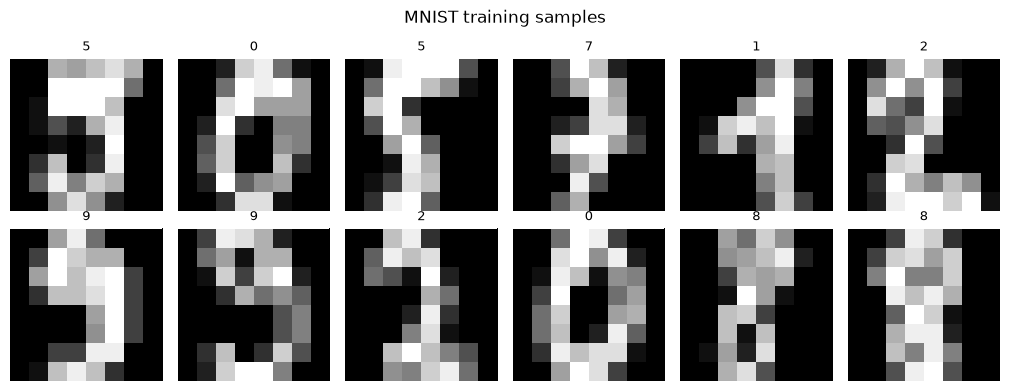

In [16]:
class_names_mnist = [str(i) for i in np.unique(y_mn_train)]
mnist_images = (X_mn_train[:12] / 255.0).reshape(-1, *mnist_shape)
plot_image_gallery(
    mnist_images, y_mn_train[:12], class_names_mnist, mnist_shape,
    n=12, title="MNIST training samples",
)

Each digit varies in slant, thickness, and position. $k$-NN does not know that pixels are
spatially arranged: it treats the 784 values as independent coordinates. Pixel-space
distance is a crude notion of digit similarity, which is exactly why a convolutional
network eventually wins. Still, neighbour voting works well because similar digits tend
to have similar ink patterns.

### 2.2 Choose $k$

Cross-validating on the full 6,000 training images would be slow. We tune on a
stratified 2,000-image subset and then refit the chosen model on all 6,000. This is a
standard compromise: model selection on a manageable sample, final fit on more data.

Tuning on 1437 images with 3-fold CV


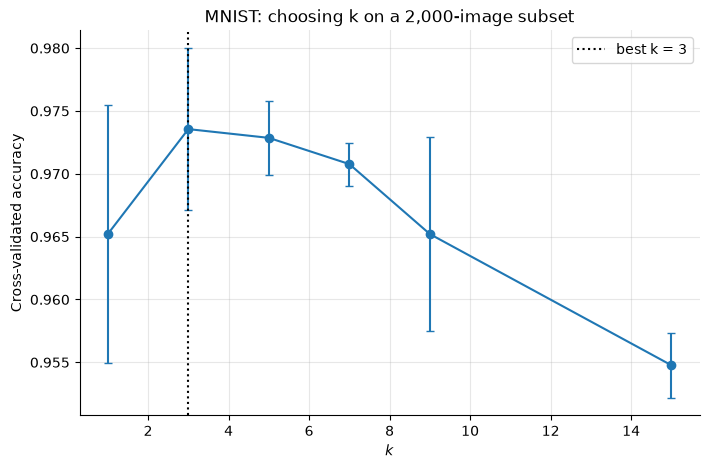

k =  1   CV accuracy = 0.9652 +/- 0.0103
k =  3   CV accuracy = 0.9736 +/- 0.0065
k =  5   CV accuracy = 0.9729 +/- 0.0030
k =  7   CV accuracy = 0.9708 +/- 0.0017
k =  9   CV accuracy = 0.9652 +/- 0.0077
k = 15   CV accuracy = 0.9548 +/- 0.0026

Selected k = 3


In [17]:
n_tune = min(2000, len(X_mn_train))
if n_tune < len(X_mn_train):
    X_mn_tune, _, y_mn_tune, _ = train_test_split(
        X_mn_train, y_mn_train, train_size=n_tune,
        stratify=y_mn_train, random_state=RANDOM_STATE,
    )
else:
    X_mn_tune, y_mn_tune = X_mn_train, y_mn_train
print(f"Tuning on {len(X_mn_tune)} images with 3-fold CV")

ks_mnist = [1, 3, 5, 7, 9, 15]
rows_mnist = tune_k(X_mn_tune, y_mn_tune, ks_mnist, cv_splits=3)
best_mnist = best_row(rows_mnist)

plot_k_curve(rows_mnist, "MNIST: choosing k on a 2,000-image subset")

for row in rows_mnist:
    print(f"k = {row['k']:2d}   CV accuracy = {row['mean']:.4f} +/- {row['std']:.4f}")
print(f"\nSelected k = {best_mnist['k']}")

MNIST is high-dimensional but not *statistically* high-dimensional in the way random
Gaussian data are: the digits lie near a low-dimensional manifold, so neighbours remain
meaningful. Small odd values of $k$ (3 or 5) usually win. $k=1$ is often close behind but
has no smoothing and is sensitive to label noise.

### 2.3 Raw pixels versus PCA

Two models with the same $k$:

- **raw pixels:** 784 features, brute-force neighbour search;
- **PCA-50:** project onto the 50 leading principal components, then search.

PCA is fitted on the training set only. It often *improves* accuracy slightly by
denoising, and it makes prediction much faster because distances are computed in 50
dimensions instead of 784.

In [ ]:
best_k_mnist = best_mnist["k"]

mnist_raw = fit_and_time(
    build_knn_pipeline(best_k_mnist),
    X_mn_train, y_mn_train, X_mn_test, y_mn_test,
)
mnist_pca = fit_and_time(
    build_knn_pipeline(best_k_mnist, n_components=50),
    X_mn_train, y_mn_train, X_mn_test, y_mn_test,
)

print(f"{'model':<22}{'test accuracy':>15}{'seconds':>10}{'ms/query':>10}")
print("-" * 57)
for name, result in [("raw pixels", mnist_raw), ("PCA-50", mnist_pca)]:
    print(f"{name:<22}{result['acc']:>15.4f}{result['seconds']:>10.2f}"
          f"{result['ms_per_query']:>10.3f}")

raw_queries = len(X_mn_test) * len(X_mn_train) * X_mn_train.shape[1]
pca_queries = len(X_mn_test) * len(X_mn_train) * 50


def format_operations(value):
    if value >= 1e9:
        return f"{value / 1e9:.1f} billion"
    return f"{value / 1e6:.0f} million"


print(f"\nRough distance operations, raw: {format_operations(raw_queries)}")
print(f"Rough distance operations, PCA: {format_operations(pca_queries)}")

The speed-up is roughly the ratio of dimensions, $784/50 \approx 16$. On a modern BLAS
implementation the constant factor is not exactly 16, but the order of magnitude is
clear. If accuracy holds up, PCA is almost free performance.

### 2.4 Confusion matrix and errors

We diagnose the better of the two models on the test set.

In [ ]:
if mnist_pca["acc"] >= mnist_raw["acc"]:
    mnist_best, mnist_best_name = mnist_pca, "PCA-50 + k-NN"
else:
    mnist_best, mnist_best_name = mnist_raw, "raw pixels + k-NN"

mnist_pred = mnist_best["y_pred"]
print(f"Diagnosing: {mnist_best_name}")
print(f"Test accuracy: {mnist_best['acc']:.4f}\n")
print(classification_report(
    y_mn_test, mnist_pred,
    target_names=class_names_mnist, digits=3,
))

cm_mnist = confusion_matrix(y_mn_test, mnist_pred)
fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay(cm_mnist, display_labels=class_names_mnist).plot(
    ax=ax, cmap="Blues", colorbar=False, values_format="d"
)
ax.set_title(f"MNIST confusion matrix ({mnist_best_name}, k = {best_k_mnist})")
plt.show()

In [ ]:
wrong = np.where(mnist_pred != y_mn_test)[0]
print(f"Misclassified: {len(wrong)} / {len(y_mn_test)} test images")

if len(wrong):
    n_show = min(8, len(wrong))
    fig, axes = plt.subplots(2, 4, figsize=(10, 5))
    for ax in axes.ravel():
        ax.axis("off")
    for ax, idx in zip(axes.ravel(), wrong[:n_show]):
        ax.imshow(X_mn_test[idx].reshape(mnist_shape), cmap="gray")
        ax.set_title(
            f"true: {class_names_mnist[y_mn_test[idx]]}   "
            f"pred: {class_names_mnist[mnist_pred[idx]]}",
            fontsize=9, color="darkred",
        )
    fig.suptitle("Typical k-NN errors on MNIST")
    fig.tight_layout()
    plt.show()
else:
    print("No errors on this test subsample.")

Most errors confuse visually similar digits: 4/9, 3/5, 7/1, and some 8/9. A human would
often make the same mistake on the worst examples. This is a useful reminder that 97%
accuracy does not mean the model has learned the concept of a digit --- it has learned a
local similarity metric.

**Takeaways for MNIST**

- $k$-NN is a strong baseline on small images;
- tune $k$ on a subset, then refit on more data;
- PCA reduces prediction cost dramatically and may even help accuracy;
- per-class metrics matter: some digits are systematically harder.

## Part 3 --- ImageNet

ImageNet is the large-scale image benchmark: about 1.3 million training images in 1,000
classes, with images around $469 \times 387$ pixels. It is not downloadable inside this
notebook, and raw-pixel $k$-NN is not a competitive ImageNet classifier in practice.
The purpose of this section is to show **why** that is true and what the alternatives
are.

### 3.1 Configure a local copy

Point the notebook at a folder of class subfolders:

```
data/imagenet/
├── n01440764/     *.JPEG   (tench)
├── n01443537/     *.JPEG   (goldfish)
├── n01484850/     *.JPEG   (great white shark)
└── ...
```

A single wrapper directory named `train`, `training`, or `images` is followed
automatically. You can also point at the validation split.

Set the path either here or with an environment variable before starting Jupyter:

```bash
export IMAGENET_ROOT=/path/to/imagenet/train
jupyter notebook Code/knn_datasets_worksheet.ipynb
```

To keep memory and time reasonable we load at most 6 classes and 80 images per class,
resized to $32 \times 32$ RGB. Change the constants below if you want a bigger sample.

In [ ]:
IMAGENET_ROOT = Path(os.environ.get("IMAGENET_ROOT", "data/imagenet")).expanduser()
IMAGE_SIZE = (32, 32)
MAX_CLASSES = 6
MAX_PER_CLASS = 80
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

print(f"ImageNet root: {IMAGENET_ROOT.resolve()}")
print(f"Folder exists: {IMAGENET_ROOT.is_dir()}")
print(f"Loading at most {MAX_CLASSES} classes x {MAX_PER_CLASS} images "
      f"at {IMAGE_SIZE[0]}x{IMAGE_SIZE[1]} pixels")

### 3.2 Folder loader and synthetic fallback

The loader below is intentionally small: it discovers class folders, takes a random
subset, resizes each image with Pillow, and returns a flattened float array in $[0,1]$.

If no real folder is available, `make_synthetic_images` draws six classes of coloured
shapes (disk, square, triangle, ring, stripes, checkerboard) with randomised position,
size, brightness, a distractor patch, and noise. The images deliberately overlap enough
that the task is not trivial. They are *not* a substitute for ImageNet, but they exercise
exactly the same code: folder-style labels, high-dimensional pixels, PCA, and $k$-NN.

In [ ]:
def find_class_dirs(root):
    # Return immediate subdirectories of root, descending through one wrapper folder.
    root = Path(root)
    if not root.is_dir():
        return []
    wrappers = {"train", "training", "images", "imagenet"}
    current = root
    for _ in range(3):
        subdirs = [p for p in current.iterdir() if p.is_dir()]
        if len(subdirs) == 1 and subdirs[0].name.lower() in wrappers:
            current = subdirs[0]
        else:
            break
    return [p for p in sorted(current.iterdir()) if p.is_dir()]


def load_image_folder_dataset(root, image_size=(32, 32), max_classes=6,
                              max_per_class=80, seed=0):
    # Load a small ImageFolder-style subset as flattened RGB float images.
    from PIL import Image

    class_dirs = []
    for directory in find_class_dirs(root):
        has_image = any(
            f.is_file() and f.suffix.lower() in IMAGE_EXTENSIONS
            for f in directory.iterdir()
        )
        if has_image:
            class_dirs.append(directory)

    if not class_dirs:
        raise FileNotFoundError(f"No class folders with images found under {root}")

    rng = np.random.default_rng(seed)
    chosen = rng.permutation(len(class_dirs))[:max_classes]
    class_dirs = [class_dirs[i] for i in chosen]

    X, y, names = [], [], []
    for label, directory in enumerate(class_dirs):
        files = sorted(
            f for f in directory.iterdir()
            if f.is_file() and f.suffix.lower() in IMAGE_EXTENSIONS
        )
        if len(files) > max_per_class:
            pick = rng.choice(len(files), size=max_per_class, replace=False)
            files = [files[i] for i in sorted(pick)]
        for path in files:
            with Image.open(path) as image:
                array = np.asarray(
                    image.convert("RGB").resize(image_size), dtype=np.float32
                ) / 255.0
            X.append(array.ravel())
            y.append(label)
        names.append(directory.name)

    return np.asarray(X, dtype=np.float32), np.asarray(y, dtype=np.int64), names


def draw_synthetic_image(rng, label, size, colour):
    # Draw one class-specific shape on a noisy dark background.
    yy, xx = np.mgrid[0:size, 0:size]
    x = (xx - size / 2.0) / (size / 2.0)
    y = (yy - size / 2.0) / (size / 2.0)
    cx, cy = rng.uniform(-0.25, 0.25, size=2)
    radius = rng.uniform(0.35, 0.60)

    background = 0.15 + 0.10 * rng.random((size, size, 1))
    image = np.repeat(background, 3, axis=2)

    if label == 0:      # disk
        mask = (x - cx) ** 2 + (y - cy) ** 2 < radius ** 2
    elif label == 1:    # square
        mask = (np.abs(x - cx) < radius) & (np.abs(y - cy) < radius)
    elif label == 2:    # triangle
        top = cy - radius
        half_width = (y - top) / 2.0
        mask = (y > top) & (y < cy + radius) & (np.abs(x - cx) < half_width)
    elif label == 3:    # ring
        d2 = (x - cx) ** 2 + (y - cy) ** 2
        mask = (d2 > (0.55 * radius) ** 2) & (d2 < radius ** 2)
    elif label == 4:    # diagonal stripes
        phase = rng.uniform(0, 2 * np.pi)
        frequency = rng.uniform(6.0, 10.0)
        mask = np.sin(frequency * (x + y) + phase) > 0
    else:               # checkerboard
        frequency = rng.uniform(4.0, 7.0)
        phase = rng.uniform(0, np.pi)
        mask = np.sin(frequency * x + phase) * np.sin(frequency * y + phase) > 0

    # Per-image colour and brightness jitter make the classes overlap more.
    colour = np.clip(
        colour * rng.uniform(0.80, 1.10, size=3) * rng.uniform(0.70, 1.00),
        0.0,
        1.0,
    )
    image[mask] = colour

    # Add a neutral-coloured distractor patch in most images.
    if rng.random() < 0.85:
        dx, dy = rng.uniform(-0.6, 0.6, size=2)
        half_w, half_h = rng.uniform(0.06, 0.18, size=2)
        clutter = (np.abs(x - dx) < half_w) & (np.abs(y - dy) < half_h)
        image[clutter] = np.clip(0.40 + 0.15 * rng.random(3), 0.0, 1.0)

    image = image + rng.normal(0.0, 0.10, image.shape)
    return np.clip(image, 0.0, 1.0)


def make_synthetic_images(n_per_class=80, image_size=32, n_classes=6, seed=0):
    # Six classes of coloured shapes with the same tensor layout as ImageNet.
    rng = np.random.default_rng(seed)
    colours = np.array(
        [
            [0.90, 0.20, 0.20],
            [0.20, 0.40, 0.90],
            [0.20, 0.80, 0.30],
            [0.95, 0.85, 0.20],
            [0.70, 0.30, 0.90],
            [0.20, 0.85, 0.85],
        ]
    )
    names = [
        "red disk",
        "blue square",
        "green triangle",
        "yellow ring",
        "purple stripes",
        "cyan checkerboard",
    ]
    X, y = [], []
    for label in range(n_classes):
        for _ in range(n_per_class):
            X.append(draw_synthetic_image(rng, label, image_size, colours[label]).ravel())
            y.append(label)
    return np.asarray(X, dtype=np.float32), np.asarray(y, dtype=np.int64), names

### 3.3 Load images

We try the real folder first and fall back to synthetic images only if it is absent or
unreadable. The printed source tells you which path was taken.

In [ ]:
try:
    if not IMAGENET_ROOT.is_dir():
        raise FileNotFoundError(f"{IMAGENET_ROOT} does not exist")
    X_img, y_img, img_class_names = load_image_folder_dataset(
        IMAGENET_ROOT, image_size=IMAGE_SIZE,
        max_classes=MAX_CLASSES, max_per_class=MAX_PER_CLASS,
        seed=RANDOM_STATE,
    )
    image_source = f"real images from {IMAGENET_ROOT}"
except Exception as exc:
    print(f"Using the synthetic fallback ({type(exc).__name__}: {exc})")
    X_img, y_img, img_class_names = make_synthetic_images(
        n_per_class=MAX_PER_CLASS, image_size=IMAGE_SIZE[0],
        n_classes=MAX_CLASSES, seed=RANDOM_STATE,
    )
    image_source = "synthetic shapes (fallback)"

print(f"Source: {image_source}")
print(f"Images: {X_img.shape}  (n, 32*32*3)")
print(f"Classes: {len(img_class_names)} -> {img_class_names}")
print("Class counts:", np.bincount(y_img))

gallery = X_img[:12].reshape(-1, *IMAGE_SIZE, 3)
plot_image_gallery(
    gallery, y_img[:12], img_class_names, IMAGE_SIZE[:2],
    n=12, title=f"Training examples: {image_source}",
)

Each image is now a vector of $32 \times 32 \times 3 = 3{,}072$ numbers. Even at this
small resolution, one image has almost four times as many features as MNIST.

### 3.4 Tune and evaluate

The workflow is unchanged, but keep an eye on two numbers: accuracy and prediction time.
We reuse the same $k$ for a raw-pixel model and a PCA-40 model.

In [ ]:
X_im_train, X_im_test, y_im_train, y_im_test = train_test_split(
    X_img, y_img, test_size=0.25, stratify=y_img, random_state=RANDOM_STATE
)
print(f"Train: {X_im_train.shape}  Test: {X_im_test.shape}")

ks_img = [1, 3, 5, 7, 9, 15]
rows_img = tune_k(X_im_train, y_im_train, ks_img, cv_splits=3)
best_img = best_row(rows_img)

plot_k_curve(rows_img, "Images: choosing k with 3-fold CV")
for row in rows_img:
    print(f"k = {row['k']:2d}   CV accuracy = {row['mean']:.3f} +/- {row['std']:.3f}")
print(f"\nSelected k = {best_img['k']}")

In [ ]:
best_k_img = best_img["k"]
img_raw = fit_and_time(
    build_knn_pipeline(best_k_img),
    X_im_train, y_im_train, X_im_test, y_im_test,
)
img_pca = fit_and_time(
    build_knn_pipeline(best_k_img, n_components=40),
    X_im_train, y_im_train, X_im_test, y_im_test,
)

print(f"{'model':<22}{'test accuracy':>15}{'seconds':>10}{'ms/query':>10}")
print("-" * 57)
for name, result in [("raw pixels", img_raw), ("PCA-40", img_pca)]:
    print(f"{name:<22}{result['acc']:>15.4f}{result['seconds']:>10.2f}"
          f"{result['ms_per_query']:>10.3f}")

img_raw_acc, img_raw_ms = img_raw["acc"], img_raw["ms_per_query"]
img_pca_acc, img_pca_ms = img_pca["acc"], img_pca["ms_per_query"]

### 3.5 Why raw-pixel k-NN does not scale to ImageNet

Two effects appear as the dimension grows.

**1. Distances concentrate.** A useful diagnostic is the ratio between the nearest and
the farthest distance from a query. If that ratio is close to one, "nearest" is barely
nearer than "farthest", and neighbour voting loses its meaning.

**2. Prediction cost explodes.** Brute force compares each query with every stored
training image in every pixel. For full ImageNet with raw pixels this is hopeless.

The next cell measures distance concentration on each dataset, then on uniformly random
points as a baseline. The baseline shows the pure effect of dimension; real data can do
better when it lies near a low-dimensional manifold.

In [ ]:
def distance_concentration(X_query, X_reference, max_queries=40, random_state=42):
    # Mean ratio of nearest to farthest distance over a random sample of queries.
    rng = np.random.default_rng(random_state)
    idx = rng.permutation(len(X_query))[:max_queries]
    ratios = []
    for query in X_query[idx]:
        distances = np.linalg.norm(X_reference - query, axis=1)
        ratios.append(distances.min() / distances.max())
    return float(np.mean(ratios))


for name, (queries, reference) in {
    "Iris": (X_ir_test, X_ir_train),
    "MNIST": (X_mn_test, X_mn_train),
    "Images": (X_im_test, X_im_train),
}.items():
    ratio = distance_concentration(queries, reference)
    print(f"{name:<8s} nearest/farthest distance ratio = {ratio:.3f}")

print("\nUniform random baseline (40 queries, 200 reference points):")
for d in [4, 64, 3072]:
    rng = np.random.default_rng(RANDOM_STATE)
    A = rng.random((40, d))
    B = rng.random((200, d))
    ratio = distance_concentration(A, B, max_queries=40)
    print(f"d = {d:4d}   nearest/farthest distance ratio = {ratio:.3f}")

For uniformly random points the ratio climbs toward one as the dimension grows: about
0.14 at $d=4$, 0.68 at $d=64$, and 0.95 at $d=3072$. In that regime "nearest" is almost
meaningless.

Real data is not uniformly random. Iris has a tiny ratio because the classes form compact
clusters. MNIST and the 32x32 images have ratios between 0.28 and 0.39: higher than Iris,
but far below random points of the same dimension. That happens because digits and simple
shapes lie near a low-dimensional manifold, so genuine neighbours still exist. This is
exactly why $k$-NN remains useful on MNIST and on small image datasets.

Natural ImageNet images at full resolution are much less forgiving. Pixel distances
concentrate strongly, and even where they do not, the brute-force cost is prohibitive.
Real ImageNet pipelines therefore do **not** run $k$-NN on raw pixels. They

- extract features with a pretrained CNN or vision transformer,
- optionally reduce them with PCA or a learned projection,
- then run $k$-NN or a linear classifier on the embeddings, or
- use approximate nearest-neighbour indexes (FAISS, HNSW, Annoy) for retrieval.

The k-NN *idea* survives; the raw pixel representation does not.

### 3.6 Confusion matrix on the image subset

In [ ]:
if img_pca["acc"] >= img_raw["acc"]:
    img_best, img_best_name = img_pca, "PCA-40 + k-NN"
else:
    img_best, img_best_name = img_raw, "raw pixels + k-NN"

img_pred = img_best["y_pred"]
print(f"Diagnosing: {img_best_name}")
print(f"Test accuracy: {img_best['acc']:.4f}\n")
print(classification_report(
    y_im_test, img_pred, target_names=img_class_names, digits=3, zero_division=0,
))

cm_img = confusion_matrix(y_im_test, img_pred)
fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay(cm_img, display_labels=img_class_names).plot(
    ax=ax, cmap="Blues", colorbar=False, values_format="d"
)
plt.setp(ax.get_xticklabels(), rotation=30, ha="right")
ax.set_title(f"Image subset confusion matrix ({img_best_name}, k = {best_k_img})")
plt.show()

In [ ]:
wrong_img = np.where(img_pred != y_im_test)[0]
print(f"Misclassified: {len(wrong_img)} / {len(y_im_test)} images")

if len(wrong_img):
    n_show = min(8, len(wrong_img))
    fig, axes = plt.subplots(2, 4, figsize=(10, 5))
    for ax in axes.ravel():
        ax.axis("off")
    for ax, idx in zip(axes.ravel(), wrong_img[:n_show]):
        ax.imshow(X_im_test[idx].reshape(*IMAGE_SIZE, 3))
        ax.set_title(
            f"true: {img_class_names[y_im_test[idx]]}\n"
            f"pred: {img_class_names[img_pred[idx]]}",
            fontsize=8, color="darkred",
        )
    fig.suptitle("Misclassified images")
    fig.tight_layout()
    plt.show()
else:
    print("No errors on this small test subset.")

**Takeaways for ImageNet**

- the same $k$-NN code runs on images, but the representation matters more than the
  classifier;
- $32 \times 32$ pixels is already 3,072 features, and real images are far larger;
- PCA gives a large speed-up, but it is a linear projection and cannot fix a bad
  representation;
- for real work, use CNN/transformer embeddings and approximate nearest-neighbour search.

## Part 4 --- Putting the three datasets side by side

In [ ]:
summary = [
    {
        "name": "Iris",
        "n_train": len(X_ir_train),
        "n_test": len(X_ir_test),
        "n_features": x_iris.shape[1],
        "n_classes": len(class_names_iris),
        "best_k": best_k_iris,
        "acc": iris_acc,
        "ms": iris_ms,
    },
    {
        "name": "MNIST (raw)",
        "n_train": len(X_mn_train),
        "n_test": len(X_mn_test),
        "n_features": X_mn_train.shape[1],
        "n_classes": len(class_names_mnist),
        "best_k": best_k_mnist,
        "acc": mnist_raw["acc"],
        "ms": mnist_raw["ms_per_query"],
    },
    {
        "name": "MNIST (PCA-50)",
        "n_train": len(X_mn_train),
        "n_test": len(X_mn_test),
        "n_features": X_mn_train.shape[1],
        "n_classes": len(class_names_mnist),
        "best_k": best_k_mnist,
        "acc": mnist_pca["acc"],
        "ms": mnist_pca["ms_per_query"],
    },
    {
        "name": "Images (raw)",
        "n_train": len(X_im_train),
        "n_test": len(X_im_test),
        "n_features": X_im_train.shape[1],
        "n_classes": len(img_class_names),
        "best_k": best_k_img,
        "acc": img_raw["acc"],
        "ms": img_raw["ms_per_query"],
    },
    {
        "name": "Images (PCA-40)",
        "n_train": len(X_im_train),
        "n_test": len(X_im_test),
        "n_features": X_im_train.shape[1],
        "n_classes": len(img_class_names),
        "best_k": best_k_img,
        "acc": img_pca["acc"],
        "ms": img_pca["ms_per_query"],
    },
]

header = (f"{'dataset':<20}{'train':>7}{'test':>6}{'features':>9}"
          f"{'classes':>8}{'k':>4}{'test acc':>10}{'ms/query':>10}")
print(header)
print("-" * len(header))
for row in summary:
    print(f"{row['name']:<20}{row['n_train']:>7d}{row['n_test']:>6d}"
          f"{row['n_features']:>9d}{row['n_classes']:>8d}{row['best_k']:>4d}"
          f"{row['acc']:>10.3f}{row['ms']:>10.3f}")

Read the table as a story about representation, not about the classifier:

- Iris is low-dimensional and easy; $k$-NN is near-optimal.
- MNIST is higher-dimensional but has strong local structure; $k$-NN is a solid baseline.
- Raw image pixels are a weak representation; the same algorithm degrades and becomes
  expensive.
- PCA helps with cost (and sometimes accuracy) by exploiting correlations between
  features. It does not create information.

## Checklist for any k-NN experiment

| Step | Rule |
|---|---|
| Split | Split into train/test **before** fitting any preprocessing. |
| Scaling | Standardise features, inside a `Pipeline` when cross-validating. |
| $k$ | Tune with stratified CV; odd $k$ avoids ties in binary problems. |
| Weights | Try `weights="distance"`; it helps when neighbour distances vary. |
| Metric | Euclidean for standardised tabular data, cosine for text/embeddings. |
| High dimension | Reduce with PCA/embeddings, or use approximate nearest neighbours. |
| Cost | Prediction is $O(n_{\text{train}} n_{\text{test}} d)$ for brute force. |
| Imbalance | Report per-class precision/recall, not only accuracy. |
| Leakage | Never fit a scaler or PCA on the full dataset before splitting. |
| Reproducibility | Fix seeds for the split, CV folds, and any subsampling. |

## Exercises

1. **Sample size.** Change `n_train` in `load_mnist` from 6,000 to 2,000 and to 12,000.
   Plot test accuracy and prediction time against training size.
2. **$k=1$.** Confirm that the training accuracy of a 1-NN model is exactly 1.0. Explain
   why, then compare its test accuracy with $k=5$.
3. **Distance weighting.** Add `weights="distance"` to `build_knn_pipeline` and rerun all
   three datasets. Where does it help?
4. **Cosine distance.** Compare `metric="euclidean"` with `metric="cosine"` on MNIST and
   on the image data. Explain the difference.
5. **PCA variance.** Plot the cumulative explained variance on MNIST. How many components
   are needed for 90%? How does accuracy change if you use that many?
6. **Distance concentration.** Extend the concentration experiment to Gaussian random
   data in dimensions 2, 10, 50, 200, and 1000. Compare with the image curve.
7. **Real ImageNet.** If you have a local copy, load 10 classes and compare raw pixels
   with features from a pretrained network. Use a nearest-neighbour index if the sample
   is large.
8. **Full MNIST (optional).** Run the tuned pipeline on all 60,000 training images.
   Measure fit time and prediction time, and explain why brute force becomes impractical
   for interactive use.

## Further reading

- T. Cover and P. Hart, "Nearest Neighbor Pattern Classification", *IEEE Transactions on
  Information Theory*, 1967.
- T. Hastie, R. Tibshirani, and J. Friedman, *The Elements of Statistical Learning*,
  Chapter 2 and Chapter 13.
- scikit-learn user guide, *Nearest Neighbors* and *Approximate Nearest Neighbors*.
- J. Deng et al., "ImageNet: A Large-Scale Hierarchical Image Database", *CVPR*, 2009.
- J. Johnson, M. Douze, and H. Jegou, "Billion-scale similarity search with GPUs"
  (FAISS), *IEEE Transactions on Big Data*, 2019.